<a href="https://colab.research.google.com/github/Min414/Name-That-LLM/blob/main/NameThatLLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

df = pd.read_csv("train.csv", encoding="utf-8")

print(df["model"].value_counts())   # check class balance

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(df, df["model"], groups=df["prompt_group"]))
train, test = df.iloc[tr], df.iloc[te]

vec = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, sublinear_tf=True)
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(vec.fit_transform(train["text"]), train["model"])

print(classification_report(test["model"], clf.predict(vec.transform(test["text"]))))

model
gpt-6-astra      2704
gpt-5.6-luna     2341
gpt-5.6-sol      2338
gpt-5.6-terra    2336
Name: count, dtype: int64
               precision    recall  f1-score   support

 gpt-5.6-luna       0.41      0.35      0.38       468
  gpt-5.6-sol       0.35      0.28      0.31       467
gpt-5.6-terra       0.46      0.51      0.49       467
  gpt-6-astra       0.54      0.66      0.59       540

     accuracy                           0.46      1942
    macro avg       0.44      0.45      0.44      1942
 weighted avg       0.44      0.46      0.45      1942



In [2]:
from sklearn.pipeline import make_union
from sklearn.svm import LinearSVC

vec = make_union(
    TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=50000),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, max_features=100000),
)
clf = LinearSVC(class_weight="balanced")

               precision    recall  f1-score   support

 gpt-5.6-luna       0.42      0.40      0.41       468
  gpt-5.6-sol       0.38      0.33      0.35       467
gpt-5.6-terra       0.48      0.51      0.49       467
  gpt-6-astra       0.58      0.64      0.61       540

     accuracy                           0.48      1942
    macro avg       0.46      0.47      0.47      1942
 weighted avg       0.47      0.48      0.47      1942



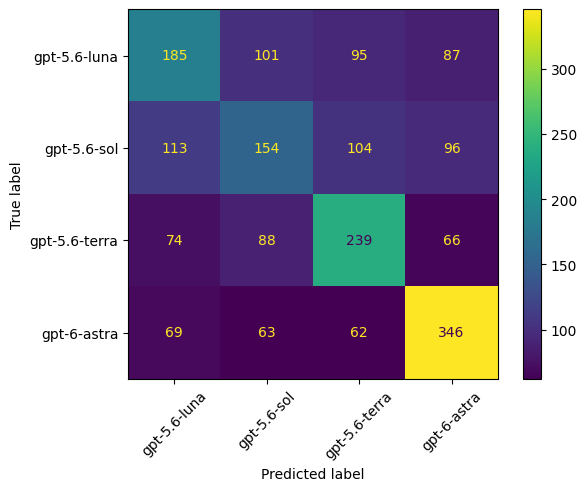

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
Xtr = vec.fit_transform(train["text"])
clf.fit(Xtr, train["model"])

pred = clf.predict(vec.transform(test["text"]))
print(classification_report(test["model"], pred))
ConfusionMatrixDisplay.from_predictions(test["model"], pred, xticks_rotation=45)

In [7]:
!pip install -q transformers datasets accelerate

import numpy as np
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)
from sklearn.metrics import accuracy_score, f1_score

labels = sorted(df["model"].unique())
l2i = {l: i for i, l in enumerate(labels)}

def prep(d):
    return Dataset.from_dict({"text": d["text"].tolist(),
                              "label": d["model"].map(l2i).tolist()})

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
enc = lambda b: tok(b["text"], truncation=True, max_length=256)
tr_ds = prep(train).map(enc, batched=True)
te_ds = prep(test).map(enc, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=len(labels))

def metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"acc": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments("out", per_device_train_batch_size=16, num_train_epochs=3,
                         eval_strategy="epoch", fp16=True, report_to="none")
Trainer(model=model, args=args, train_dataset=tr_ds, eval_dataset=te_ds,
        processing_class=tok, compute_metrics=metrics).train()

Map:   0%|          | 0/7777 [00:00<?, ? examples/s]

Map:   0%|          | 0/1942 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Acc,Macro F1
1,No log,1.268511,0.391349,0.338846
2,1.345159,1.200954,0.430999,0.377524
3,1.173015,1.229010,0.459320,0.452443


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1461, training_loss=1.162873734846905, metrics={'train_runtime': 209.0436, 'train_samples_per_second': 111.608, 'train_steps_per_second': 6.989, 'total_flos': 1531629753927504.0, 'train_loss': 1.162873734846905, 'epoch': 3.0})

              precision    recall  f1-score   support

         5.6       0.86      0.84      0.85      1402
           6       0.61      0.64      0.62       540

    accuracy                           0.78      1942
   macro avg       0.73      0.74      0.74      1942
weighted avg       0.79      0.78      0.79      1942



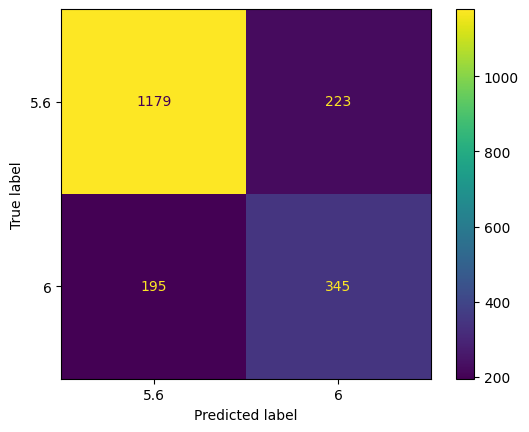

In [8]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# relabel: 5.6 family vs 6
train2 = train["model"].str.startswith("gpt-5.6").map({True: "5.6", False: "6"})
test2 = test["model"].str.startswith("gpt-5.6").map({True: "5.6", False: "6"})

Xtr = vec.fit_transform(train["text"])
clf2 = LinearSVC(class_weight="balanced").fit(Xtr, train2)

pred2 = clf2.predict(vec.transform(test["text"]))
print(classification_report(test2, pred2))
ConfusionMatrixDisplay.from_predictions(test2, pred2)

In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline, make_union

y2 = df["model"].str.startswith("gpt-5.6").map({True: "5.6", False: "6"})

pipe = make_pipeline(
    make_union(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=50000),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, max_features=100000),
    ),
    LinearSVC(class_weight="balanced"),
)

cv = GroupKFold(n_splits=5)
for name, y in [("4-class", df["model"]), ("2-class", y2)]:
    s = cross_val_score(pipe, df["text"], y, groups=df["prompt_group"], cv=cv, scoring="f1_macro")
    print(name, f"macro F1 = {s.mean():.3f} ± {s.std():.3f}")

4-class macro F1 = 0.461 ± 0.013
2-class macro F1 = 0.742 ± 0.004


In [10]:
import numpy as np

vec_w = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=5)
Xw = vec_w.fit_transform(df["text"])
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xw, y2)

names = np.array(vec_w.get_feature_names_out())
order = lr.coef_[0].argsort()   # classes sorted: "5.6" < "6", so positive coef = "6"

print("Most gpt-6:", list(names[order[-25:]][::-1]))
print("Most 5.6:  ", list(names[order[:25]]))

print(df.groupby(y2)["n_words"].describe()[["mean", "std"]])

Most gpt-6: ['its', 'these', 'their', 'your', 'this', 'something', 'those', 'his', 'without', 'helped', 'alongside', 'rather', 'another', 'everyday', 'against', 'generally', 'although', 're', 'makes', 'if you', 'rather than', 'you re', 'we', 'what', 'established']
Most 5.6:   ['may', 'and', 'be', 'or', 'is', 'because', 'by', 'create', 'are', 'like', 'was', 'it is', 'bright', 'were', 'they', 'may be', 'such as', 'of the', 'as', 'after', 'several', 'in', 'it', 'yet', 'long']
             mean        std
model                       
5.6    116.624376  62.051449
6      112.887944  58.673394
